# Nine-scenario analysis
Loads the saved outputs of `python -m ml.simulation.scenarios` (500 common-random-number replications). All INR values are **simulated on synthetic data**.

Re-run the scenarios with fewer replications by setting `RERUN = True`.

In [1]:
import os, sys, json
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
ROOT = os.path.abspath('..')
sys.path.insert(0, ROOT)
RERUN = False
E = os.path.join(ROOT, 'experiments')
assump = json.load(open(os.path.join(E, 'scenario_assumptions.json')))
pd.Series(assump)

currency                                                                                        INR
status                                            ILLUSTRATIVE ASSUMPTIONS for a synthetic demon...
base_material_prices                                    materials.csv unit_price_inr (illustrative)
alt_price_premium_existing_supplier                                                            0.06
alt_price_premium_substitute_supplier                                                           0.1
onboarding_fixed_cost_inr                                                                    150000
substitute_qualification_days                                                                     7
freight_rate_standard_road                                                                    0.025
freight_rate_standard_sea                                                                      0.04
expedite_freight_multiplier                                                                     3.0


In [2]:
if RERUN:
    from ml.simulation.scenarios import run_nine, summarise
    res, ctx = run_nine(reps=20, verbose=False)
    summary = summarise(res)
else:
    res = pd.read_csv(os.path.join(E, 'exp4_5_scenarios', 'scenario_replications.csv'))
    summary = pd.read_csv(os.path.join(E, 'scenario_results.csv'))
cols = ['scenario','severity','policy','disrupted_capacity_available','affected_suppliers','affected_materials','inventory_shortage_value_inr','unmet_demand_units','production_loss_cm_inr','procurement_spend_inr','transportation_cost_inr','financial_impact_inr','recovery_time_days','alt_supplier_utilisation','feasibility_full_recovery_share']
summary[cols].round(2)

,scenario,severity,policy,disrupted_capacity_available,affected_suppliers,affected_materials,inventory_shortage_value_inr,unmet_demand_units,production_loss_cm_inr,procurement_spend_inr,transportation_cost_inr,financial_impact_inr,recovery_time_days,alt_supplier_utilisation,feasibility_full_recovery_share
0,S1,Mild,A: No intervention,0.91,10.38,2.36,0.00,0.00,0.00,0.00,0.00,2565813.27,101.15,0.00,1.00
1,S2,Mild,B: Rule-based,0.91,10.38,2.36,0.00,0.00,0.00,1388.63,55.55,2565947.42,101.15,0.01,1.00
2,S3,Mild,C: Optimisation,0.91,10.38,2.36,0.00,0.00,0.00,475970.20,11902.92,2647864.04,101.15,0.05,1.00
3,S4,Moderate,A: No intervention,0.82,17.08,3.93,277483.93,47582.75,1611470.81,0.00,0.00,6148642.00,123.03,0.00,0.82
4,S5,Moderate,B: Rule-based,0.82,17.08,3.93,185217.41,29799.07,1031905.52,299205.19,11968.21,5051167.96,122.94,0.16,0.88
5,S6,Moderate,C: Optimisation,0.82,17.08,3.65,19632.65,2591.20,81903.20,8617656.05,295312.04,4478248.29,122.78,0.16,0.97
6,S7,Severe,A: No intervention,0.65,19.81,4.00,4634061.28,734086.61,25563119.22,0.00,0.00,47209441.53,127.03,0.00,0.14
7,S8,Severe,B: Rule-based,0.65,19.81,4.00,3892111.13,605270.89,21218511.25,1829213.57,73168.54,39797809.64,126.33,0.42,0.15
8,S9,Severe,C: Optimisation,0.65,19.81,3.69,526175.04,39186.30,1061860.58,46185001.45,2419705.31,11594009.28,124.64,0.23,0.88


In [3]:
pd.read_csv(os.path.join(E, 'scenario_comparison.csv')).round(0)

,severity,comparison,mean_saving_inr,ci95_low,ci95_high,share_reps_b_better
0,Mild,A: No intervention minus B: Rule-based,-134.0,-299.0,31.0,0.0
1,Mild,A: No intervention minus C: Optimisation,-82051.0,-82334.0,-81768.0,0.0
2,Mild,B: Rule-based minus C: Optimisation,-81917.0,-82232.0,-81601.0,0.0
3,Moderate,A: No intervention minus B: Rule-based,1097474.0,865700.0,1329248.0,0.0
4,Moderate,A: No intervention minus C: Optimisation,1670394.0,912145.0,2428643.0,0.0
5,Moderate,B: Rule-based minus C: Optimisation,572920.0,1523.0,1144317.0,0.0
6,Severe,A: No intervention minus B: Rule-based,7411632.0,7064133.0,7759131.0,1.0
7,Severe,A: No intervention minus C: Optimisation,35615432.0,32486710.0,38744154.0,1.0
8,Severe,B: Rule-based minus C: Optimisation,28203800.0,25269747.0,31137854.0,1.0


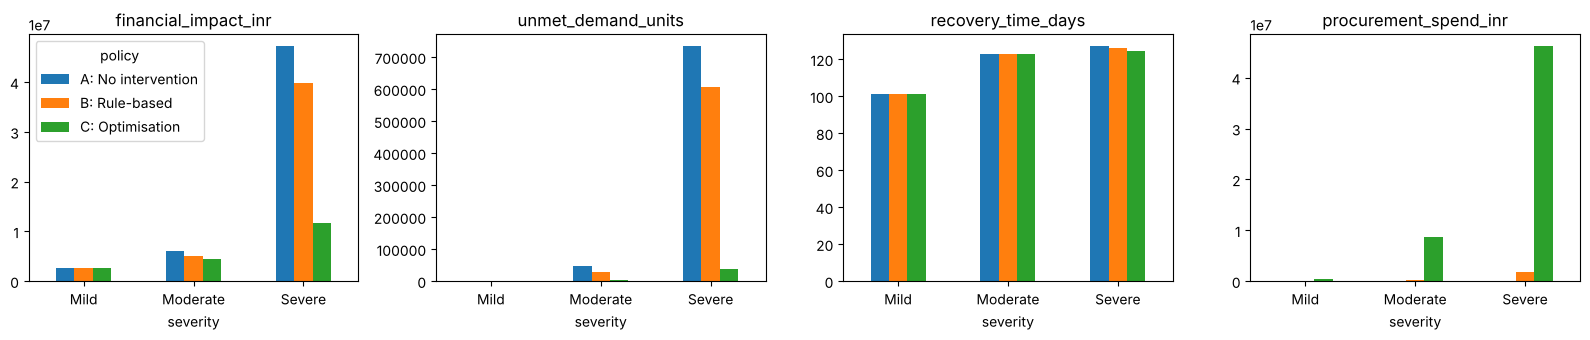

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ['financial_impact_inr', 'unmet_demand_units', 'recovery_time_days', 'procurement_spend_inr']):
    summary.pivot(index='severity', columns='policy', values=col).reindex(['Mild','Moderate','Severe']).plot.bar(ax=ax, rot=0, legend=(col=='financial_impact_inr'))
    ax.set_title(col)
plt.tight_layout()

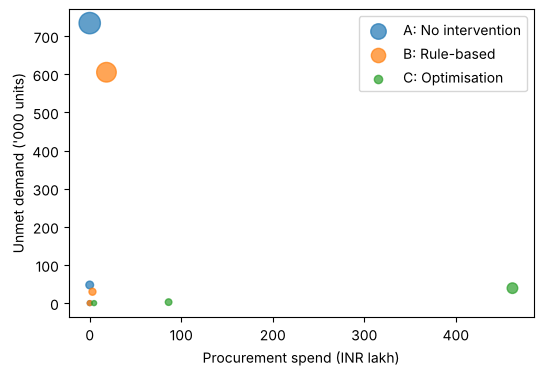

In [5]:
# cost vs risk
fig, ax = plt.subplots(figsize=(6,4))
for p, g in summary.groupby('policy'):
    ax.scatter(g.procurement_spend_inr/1e5, g.unmet_demand_units/1e3, s=g.financial_impact_inr/2e5, label=p, alpha=.7)
ax.set_xlabel('Procurement spend (INR lakh)'); ax.set_ylabel("Unmet demand ('000 units)"); ax.legend()

In [6]:
# Policy performance summary: share of replications in which each policy has the lowest impact
res.loc[res.groupby(['severity','replication']).financial_impact_inr.idxmin()].groupby('severity').policy.value_counts(normalize=True).unstack(fill_value=0).round(3)

policy,A: No intervention,B: Rule-based,C: Optimisation
severity,,,
Mild,1.000,0.000,0.000
Moderate,0.822,0.074,0.104
Severe,0.170,0.104,0.726
